# 모델 성능 고도화 2 — 랜덤 포레스트 · XGBoost 튜닝, `RandomizedSearchCV`, 모델 저장

수업 필기 `분류 모델 성능 고도화 실습 1` 을 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `머신러닝` v7 p.138~144 — 17. 모델 성능 개선)

- 어제([Day 028](../../2026-10-19/))는 결정 트리 하나를 `GridSearchCV` 로 튜닝했다. 오늘은 **랜덤 포레스트 · XGBoost** 를 튜닝하고, 후보가 많을 때 쓰는 **`RandomizedSearchCV`** 와 **모델 저장(`joblib`)** 까지.
- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.
- 스태킹은 [`stacking_classifier.ipynb`](./stacking_classifier.ipynb), 혼동 행렬 · 정밀도 · 재현율 · 특성 중요도(교재 18장)는 [`classification_evaluation.ipynb`](./classification_evaluation.ipynb) 에 있습니다.

> 데이터 : `diabetes_binary_5050split_health_indicators_BRFSS2015.csv` (미국 CDC 건강 설문 70,692명, 당뇨 0 : 1 = 50 : 50)
> ⏱️ 전체 실행 약 30분 (2코어 기준). 탐색 셀은 `n_jobs=-1` 로 CPU 코어를 모두 쓴다.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:
    plt.rcParams['font.family'] = 'Noto Sans CJK JP'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# 데이터 불러오기 (노트북과 같은 폴더)
df = pd.read_csv('./diabetes_binary_5050split_health_indicators_BRFSS2015.csv')

X_data = df.drop(columns=['Diabetes_binary'])   # 특성 21개
y_data = df['Diabetes_binary']                   # 정답 0.0 / 1.0

# 학습용 80% : 평가용 20% — 수업과 같은 분할
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=0, stratify=y_data)
print("학습용 :", X_train.shape, " 평가용 :", X_test.shape)

학습용 : (56553, 21)  평가용 : (14139, 21)


> **📝 고친 부분**
> - 경로 `C:/Users/playdata2/work/...` → `./diabetes_...csv` (노트북과 같은 폴더)
> - `display(X_data)` · `print(y_data)` · `X_train.index` 출력 → 어제 노트에서 확인했으므로 크기만 출력

## 1. 출발점 — 어제 튜닝한 결정 트리

어제 `GridSearchCV` 로 찾은 `max_depth=7, min_samples_leaf=5` 를 그대로 쓴다 (32조합 × 5-fold 를 다시 돌릴 필요 없음).

In [3]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

best_dt = DecisionTreeClassifier(max_depth=7, min_samples_leaf=5, random_state=0).fit(X_train, y_train)
pred_test_dt = best_dt.predict(X_test)

summary = []   # 모델별 결과를 모아 마지막에 비교
def record(name, how, cv_acc, model, n_fits, sec):
    pred = model.predict(X_test)
    summary.append({'모델': name, '고른 방법': how, '검증 정확도': cv_acc,
                    '평가 정확도': accuracy_score(y_test, pred), '평가 F1': f1_score(y_test, pred),
                    '학습 횟수': n_fits, '탐색 시간(초)': sec})

record('결정 트리', 'GridSearchCV 32조합 (Day 028)', 0.7419, best_dt, 160, None)
print(classification_report(y_test, pred_test_dt))

              precision    recall  f1-score   support

         0.0       0.75      0.73      0.74      7070
         1.0       0.73      0.75      0.74      7069

    accuracy                           0.74     14139
   macro avg       0.74      0.74      0.74     14139
weighted avg       0.74      0.74      0.74     14139



## 2. 랜덤 포레스트 — `GridSearchCV` (교재 p.138~140)

어제 막혔던 질문 : **랜덤 포레스트도 튜닝하면 얼마나 오를까?** (기본값 랜덤 포레스트 평가 정확도 0.7402, [Day 024](../../2026-10-13/))

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=0)

params = {
    'n_estimators': [100, 200, 300, 400],   # 트리 개수
    'max_depth': [5, 6, 7, 8, 9],           # 각 트리의 최대 깊이
    'min_samples_leaf': [2, 3, 4, 5],       # 리프 노드의 최소 샘플 수
}
n_comb = 4 * 5 * 4
print(f"조합 {n_comb}개 × fold 5개 = 학습 {n_comb * 5}번 — 트리로 치면 {sum(params['n_estimators']) * 5 * 4 * 5:,}그루")

grid_rf = GridSearchCV(estimator=rf, param_grid=params, scoring='accuracy', cv=5,
                       n_jobs=-1)          # CPU 코어를 모두 사용 (수업 코드엔 없음)
t0 = time.time()
grid_rf.fit(X_train, y_train)
sec_rf = time.time() - t0
print(f"탐색 완료 — {sec_rf/60:.1f}분")

조합 80개 × fold 5개 = 학습 400번 — 트리로 치면 100,000그루


탐색 완료 — 13.5분


In [5]:
best_rf = grid_rf.best_estimator_
print("최적 조합 :", grid_rf.best_params_)
print("검증 평균 정확도 :", round(grid_rf.best_score_, 4))
print("평가용 정확도    :", round(accuracy_score(y_test, best_rf.predict(X_test)), 4))
record('랜덤 포레스트', 'GridSearchCV 80조합', grid_rf.best_score_, best_rf, n_comb * 5, sec_rf)

최적 조합 : {'max_depth': 9, 'min_samples_leaf': 2, 'n_estimators': 400}
검증 평균 정확도 : 0.7511


평가용 정확도    : 0.7519


### 2-1. 80개 조합을 표로 — 무엇이 점수를 갈랐나

In [6]:
res_rf = pd.DataFrame(grid_rf.cv_results_)
res_rf = res_rf.rename(columns={'param_n_estimators': 'n_estimators', 'param_max_depth': 'max_depth',
                                'param_min_samples_leaf': 'min_samples_leaf'})
for c in ['n_estimators', 'max_depth', 'min_samples_leaf']:
    res_rf[c] = res_rf[c].astype(int)

# 하이퍼파라미터별로 평균 내 보기 — 값이 바뀔 때 검증 점수가 얼마나 움직이나
for c in ['max_depth', 'n_estimators', 'min_samples_leaf']:
    g = res_rf.groupby(c)['mean_test_score'].mean()
    print(f"{c:>17} :", ' · '.join(f"{k}→{v:.4f}" for k, v in g.items()), f"   (폭 {g.max()-g.min():.4f})")

res_rf[['n_estimators', 'max_depth', 'min_samples_leaf', 'mean_test_score', 'std_test_score', 'mean_fit_time', 'rank_test_score']] \
    .sort_values('rank_test_score').head(8).round(4)

        max_depth : 5→0.7435 · 6→0.7459 · 7→0.7476 · 8→0.7491 · 9→0.7501    (폭 0.0067)
     n_estimators : 100→0.7473 · 200→0.7473 · 300→0.7471 · 400→0.7473    (폭 0.0002)
 min_samples_leaf : 2→0.7473 · 3→0.7473 · 4→0.7472 · 5→0.7471    (폭 0.0002)


,n_estimators,max_depth,min_samples_leaf,mean_test_score,std_test_score,mean_fit_time,rank_test_score
67,400,9,2,0.7511,0.0041,6.8115,1
65,200,9,2,0.7509,0.0040,3.4616,2
66,300,9,2,0.7508,0.0037,5.1035,3
64,100,9,2,0.7505,0.0037,1.7020,4
71,400,9,3,0.7502,0.0036,7.2230,5
73,200,9,4,0.7501,0.0037,3.7266,6
79,400,9,5,0.7501,0.0041,7.6553,7
78,300,9,5,0.7500,0.0040,5.6219,8


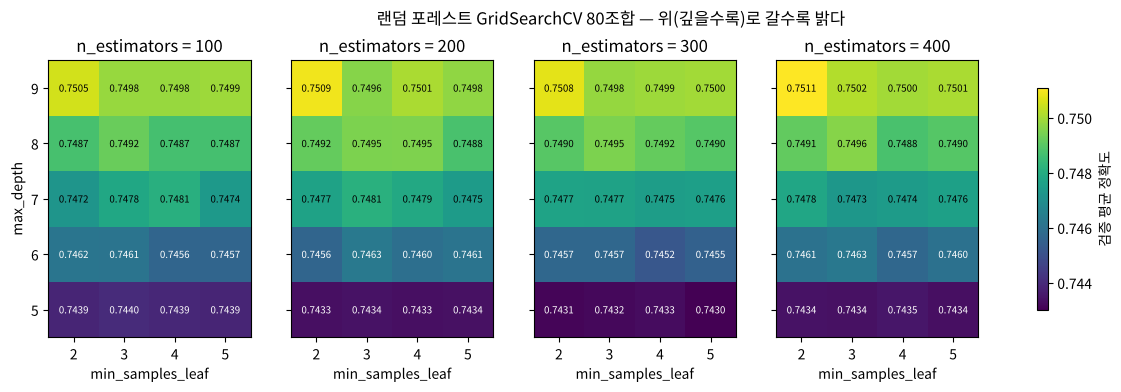

In [7]:
import os
os.makedirs('./images', exist_ok=True)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
vmin, vmax = res_rf['mean_test_score'].min(), res_rf['mean_test_score'].max()
for ax, n in zip(axes, params['n_estimators']):
    t = res_rf[res_rf['n_estimators'] == n].pivot(index='max_depth', columns='min_samples_leaf', values='mean_test_score')
    im = ax.imshow(t.values, cmap='viridis', vmin=vmin, vmax=vmax, origin='lower', aspect='auto')
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.values[i, j]:.4f}", ha='center', va='center', fontsize=7,
                    color='white' if t.values[i, j] < (vmin + vmax) / 2 else 'black')
    ax.set_xticks(range(4), t.columns); ax.set_yticks(range(5), t.index)
    ax.set_title(f'n_estimators = {n}'); ax.set_xlabel('min_samples_leaf')
axes[0].set_ylabel('max_depth')
fig.colorbar(im, ax=axes, shrink=0.8, label='검증 평균 정확도')
plt.suptitle('랜덤 포레스트 GridSearchCV 80조합 — 위(깊을수록)로 갈수록 밝다', y=1.02)
plt.savefig('./images/01_rf_grid_heatmap.png', dpi=110, bbox_inches='tight')
plt.show()

- 점수를 가르는 건 거의 **`max_depth`** (깊을수록 좋음, 후보의 끝인 9 에서 best → 범위를 더 넓혀 볼 여지가 있다).
- `n_estimators` 100 → 400 은 차이가 아주 작은데 **학습 시간은 4배**. 트리 개수는 "많을수록 안정"되지만 일정 개수 이후로는 거의 안 오른다.
- `min_samples_leaf` 2 ~ 5 는 깊이 9 트리에서는 거의 걸리지 않는 제한 (어제 결정 트리와 같은 이유).

## 3. `RandomizedSearchCV` — 후보가 많을 때 (교재 p.142~144)

`GridSearchCV` 는 **모든 조합**을 다 돌린다. 후보가 10 × 6 × 4 = **240조합**이면 5-fold 로 1,200번 학습 → 너무 오래 걸린다.
`RandomizedSearchCV` 는 그중 **`n_iter` 개만 무작위로 뽑아** 교차 검증한다.

| | `GridSearchCV` | `RandomizedSearchCV` |
|---|---|---|
| 후보를 주는 매개변수 | `param_grid` | `param_distributions` (리스트 · `range` · 확률분포) |
| 몇 개를 평가? | **모든** 조합 | **`n_iter`** 개 (무작위) |
| 재현성 | 항상 같음 | `random_state` 로 고정 |
| 장점 | 후보 안의 최적을 반드시 찾음 | 시간을 내가 정함, 범위를 넓게 줄 수 있음 |

In [8]:
from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestClassifier(random_state=0)

params_rnd = {
    'n_estimators': [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000],   # 10개
    'max_depth': [5, 6, 7, 8, 9, 10],                                     # 6개
    'min_samples_leaf': [2, 3, 4, 5],                                     # 4개 → 240조합
}

random_rf = RandomizedSearchCV(
    estimator=rf,
    param_distributions=params_rnd,
    n_iter=30,                                   # 240조합 중 30개만 무작위로 뽑아 탐색
    scoring={'accuracy': 'accuracy', 'f1': 'f1'},   # 두 지표를 함께 기록
    refit='f1',                                  # best 는 수업과 같이 f1 기준으로 고른다
    cv=5, random_state=0, n_jobs=-1)
t0 = time.time()
random_rf.fit(X_train, y_train)
sec_rnd = time.time() - t0
print(f"탐색 완료 — {sec_rnd/60:.1f}분 (조합 30개 × 5 = 150번 학습)")

탐색 완료 — 12.3분 (조합 30개 × 5 = 150번 학습)


In [9]:
res_rnd = pd.DataFrame(random_rf.cv_results_)
best_i = random_rf.best_index_
print("최적 조합 (f1 기준) :", random_rf.best_params_)
print("best_score_        :", round(random_rf.best_score_, 4), " ← 이건 F1 !")
print("같은 조합의 정확도  :", round(res_rnd.loc[best_i, 'mean_test_accuracy'], 4), " ← 랜덤 포레스트 Grid 의 0.7511 과 비교할 값")
best_rf_random = random_rf.best_estimator_
record('랜덤 포레스트', 'RandomizedSearchCV 30/240 (f1)', res_rnd.loc[best_i, 'mean_test_accuracy'],
       best_rf_random, 150, sec_rnd)

# 뽑힌 30개 조합 — 정확도 순
show = res_rnd[['param_n_estimators', 'param_max_depth', 'param_min_samples_leaf',
                'mean_test_accuracy', 'mean_test_f1', 'rank_test_f1']].sort_values('rank_test_f1')
show.head(8).round(4)

최적 조합 (f1 기준) : {'n_estimators': 800, 'min_samples_leaf': 4, 'max_depth': 10}
best_score_        : 0.7617  ← 이건 F1 !
같은 조합의 정확도  : 0.7512  ← 랜덤 포레스트 Grid 의 0.7511 과 비교할 값


,param_n_estimators,param_max_depth,param_min_samples_leaf,mean_test_accuracy,mean_test_f1,rank_test_f1
5,800,10,4,0.7512,0.7617,1
14,500,10,5,0.7511,0.7615,2
11,300,10,2,0.7512,0.7614,3
18,200,10,4,0.7508,0.7610,4
29,700,9,2,0.7507,0.7609,5
16,500,9,4,0.7502,0.7606,6
9,500,9,5,0.7501,0.7606,7
7,100,10,4,0.7502,0.7605,8


In [10]:
# 정확도로 골랐다면? — 같은 30개 중 1등이 바뀌는가
acc_best = res_rnd['mean_test_accuracy'].idxmax()
print("정확도 1등 조합 :", res_rnd.loc[acc_best, 'params'], round(res_rnd.loc[acc_best, 'mean_test_accuracy'], 4))
print("F1     1등 조합 :", res_rnd.loc[best_i, 'params'], round(res_rnd.loc[best_i, 'mean_test_f1'], 4))
print("\n30개 조합의 정확도 ↔ F1 상관계수 :", round(res_rnd['mean_test_accuracy'].corr(res_rnd['mean_test_f1']), 3))

정확도 1등 조합 : {'n_estimators': 800, 'min_samples_leaf': 4, 'max_depth': 10} 0.7512
F1     1등 조합 : {'n_estimators': 800, 'min_samples_leaf': 4, 'max_depth': 10} 0.7617

30개 조합의 정확도 ↔ F1 상관계수 : 0.998


> **📝 고친 부분** (`분류 모델 성능 고도화 실습 1`)
> - `RandomizedSearchCV` 만 `scoring='f1'` 이라 `best_score_` **0.7617 은 F1** 이다. 앞의 Grid(정확도 0.7511)보다 "더 좋아 보이는" 건 **지표가 달라서**다 — 같은 조합의 정확도는 위에서 따로 꺼냈다. 비교할 때는 **같은 지표**끼리.
> - 당뇨 0 : 1 = 50 : 50 데이터라 정확도와 F1 이 거의 같이 움직인다 (상관 위 출력). 불균형 데이터라면 F1 로 고르는 게 맞다 → [`classification_evaluation.ipynb`](./classification_evaluation.ipynb)
> - 주석 "전체 탐색 조건 240가지 -> 30가지 -> 무작위로 추출해서 탐색할 횟수" → 맞다. 10 × 6 × 4 = 240, 그중 **30개 = 12.5%** 만 평가.
> - `print("검증 완료")` → `fit` 은 **탐색(교차 검증) + 최적 조합으로 재학습**까지 한 것.

### 3-1. 30개만 뽑아도 괜찮을까? — 어제의 질문

위 Grid 80조합은 **모든 조합의 검증 점수**를 이미 알고 있다. 그러니 "그중 n 개만 무작위로 뽑았다면 1등은 몇 점이었을까?" 를 **학습 없이** 1,000번 흉내 낼 수 있다.

In [11]:
scores80 = res_rf['mean_test_score'].values
grid_best = scores80.max()
rng = np.random.default_rng(0)

n_list = [1, 5, 10, 20, 30, 40, 60, 80]
rows = []
for n in n_list:
    found = np.array([rng.choice(scores80, size=n, replace=False).max() for _ in range(1000)])
    rows.append({'n_iter': n, '평균 best': found.mean(), '최악 best': found.min(),
                 'Grid 1등과 차이(평균)': grid_best - found.mean(),
                 '상위 5% 안에 든 비율': (found >= np.quantile(scores80, 0.95)).mean()})
sim = pd.DataFrame(rows)
sim.round(4)

,n_iter,평균 best,최악 best,Grid 1등과 차이(평균),상위 5% 안에 든 비율
0,1,0.7473,0.7430,0.0038,0.054
1,5,0.7498,0.7456,0.0013,0.257
2,10,0.7503,0.7463,0.0008,0.433
3,20,0.7506,0.7492,0.0005,0.693
4,30,0.7508,0.7498,0.0003,0.842
5,40,0.7509,0.7500,0.0002,0.935
6,60,0.7510,0.7501,0.0001,0.995
7,80,0.7511,0.7511,-0.0000,1.000


In [12]:
from matplotlib.animation import FuncAnimation, PillowWriter

# 🎬 애니메이션 : 같은 80칸 — Grid 는 전부 채우고, Random 은 20칸만 무작위로
order_grid = np.arange(80)
order_rand = np.random.default_rng(3).permutation(80)[:20]
board = res_rf.sort_values(['n_estimators', 'max_depth', 'min_samples_leaf'])['mean_test_score'].values.reshape(4, 20)

fig, axes = plt.subplots(2, 2, figsize=(11, 5.4), gridspec_kw={'width_ratios': [2.2, 1]})
def draw(frame):
    for ax in axes.ravel():
        ax.clear()
    for r, (name, order) in enumerate([('GridSearchCV — 80조합 모두', order_grid), ('RandomizedSearchCV — 20조합만', order_rand)]):
        k = min(frame + 1, len(order))
        shown = np.full(80, np.nan); shown[order[:k]] = board.ravel()[order[:k]]
        ax = axes[r, 0]
        ax.imshow(shown.reshape(4, 20), cmap='viridis', vmin=vmin, vmax=vmax, aspect='auto')
        ax.set_yticks(range(4), [f'트리 {n}' for n in params['n_estimators']])
        ax.set_xticks(range(0, 20, 4), [f'깊이 {d}' for d in params['max_depth']], fontsize=8)
        ax.set_title(f'{name}  ({k}/{len(order)})', fontsize=10)
        best_so_far = np.maximum.accumulate(board.ravel()[order[:k]])
        ax2 = axes[r, 1]
        ax2.plot(range(1, k + 1), best_so_far, color='tab:orange' if r else 'tab:blue', lw=2)
        ax2.axhline(grid_best, color='gray', ls='--', lw=1); ax2.text(80, grid_best, 'Grid 1등', ha='right', va='bottom', fontsize=8)
        ax2.set_xlim(0, 81); ax2.set_ylim(vmin - 0.001, grid_best + 0.002)
        ax2.set_title(f'지금까지 best = {best_so_far[-1]:.4f}', fontsize=10); ax2.set_xlabel('평가한 조합 수')
    fig.tight_layout()

ani = FuncAnimation(fig, draw, frames=list(range(0, 80, 2)) + [79] * 8, interval=150)
ani.save('./images/anim_01_grid_vs_random.gif', writer=PillowWriter(fps=7), dpi=72)
plt.close()
print("저장 : ./images/anim_01_grid_vs_random.gif")

저장 : ./images/anim_01_grid_vs_random.gif


![Grid vs Random 애니메이션](./images/anim_01_grid_vs_random.gif)

🎬 위 : `GridSearchCV` 가 80칸을 차례로 다 채운다. 아래 : `RandomizedSearchCV` 는 **20칸만** 무작위로 찍는다. 오른쪽 "지금까지 best" 곡선을 보면 Random 이 **4분의 1 시간**으로 Grid 1등 근처까지 간다 (이 그림에선 운 좋게 1등 칸이 뽑혔다). 위 표처럼 1,000번 흉내 내면 20개만 뽑아도 1등과 평균 **0.0005** 차이, 30개면 **84%** 확률로 상위 5% 조합을 건진다.

→ 좋은 조합이 **한 칸에 몰려 있지 않고 넓게 퍼져 있으면**(여기처럼 "깊을수록 좋다" 하나로 대부분 정해지면) 무작위로 조금만 뽑아도 상위권을 건진다. 그래서 실무에서는 **넓은 범위를 Random 으로 훑고 → 좋은 근처를 Grid 로 좁혀** 찾는 경우가 많다.

## 4. XGBoost — `GridSearchCV` (교재 p.102~106 복습 + 튜닝)

In [13]:
import warnings
from xgboost import XGBClassifier

# 수업 코드에 있던 'min_samples_leaf' — XGBoost 에도 있을까?
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    a = XGBClassifier(n_estimators=100, max_depth=4, min_samples_leaf=2, random_state=0).fit(X_train, y_train)
    b = XGBClassifier(n_estimators=100, max_depth=4, min_samples_leaf=50, random_state=0).fit(X_train, y_train)
print("경고 :", str(w[0].message)[:160] if w else '(없음)')
print("min_samples_leaf=2 와 50 의 예측이 모두 같은가? :", (a.predict_proba(X_test) == b.predict_proba(X_test)).all())

경고 : [20:59:02] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "min_samples_leaf" } are not used.

min_samples_leaf=2 와 50 의 예측이 모두 같은가? : True


`min_samples_leaf` 는 **sklearn 트리(결정 트리 · 랜덤 포레스트)의 매개변수**다. XGBoost 는 모르는 이름을 **무시**하고 경고만 낸다 → 수업 코드의 144조합 중 `min_samples_leaf` 4개 후보는 **같은 모델을 4번씩** 학습한 것.
XGBoost 에서 비슷한 역할은 **`min_child_weight`** (리프에 들어갈 가중치 합의 최소값, 기본 1).

In [14]:
xgb = XGBClassifier(random_state=0, n_jobs=1)

params_xgb = {
    'n_estimators': [50, 100, 200, 300],     # 부스팅 횟수 (트리 개수)
    'learning_rate': [0.05, 0.1, 0.5],       # 한 번에 고치는 폭
    'max_depth': [3, 4, 5],                  # 각 트리의 깊이 (부스팅은 얕게)
    # 'min_samples_leaf': [2, 3, 4, 5],      # ← XGBoost 에 없는 이름이라 효과 없음 → 뺐다 (144 → 36조합)
}

grid_xgb = GridSearchCV(estimator=xgb, param_grid=params_xgb, scoring='accuracy', cv=5,
                        n_jobs=-1, return_train_score=True)
t0 = time.time()
grid_xgb.fit(X_train, y_train)
sec_xgb = time.time() - t0
best_xgb = grid_xgb.best_estimator_
print(f"탐색 완료 — {sec_xgb/60:.1f}분 (36조합 × 5 = 180번 학습)")
print("최적 조합 :", grid_xgb.best_params_)
print("검증 평균 정확도 :", round(grid_xgb.best_score_, 4))
print("평가용 정확도    :", round(accuracy_score(y_test, best_xgb.predict(X_test)), 4))
record('XGBoost', 'GridSearchCV 36조합', grid_xgb.best_score_, best_xgb, 180, sec_xgb)

탐색 완료 — 1.1분 (36조합 × 5 = 180번 학습)
최적 조합 : {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200}
검증 평균 정확도 : 0.7537
평가용 정확도    : 0.7544


> **📝 고친 부분** (`분류 모델 성능 고도화 실습 1`)
> - XGBoost `params` 의 `'min_samples_leaf'` → XGBoost 에 없는 매개변수라 **무시**된다 (조합 144개 중 108개가 중복 학습). 빼면 36조합으로 **같은 결과**를 4분의 1 시간에. 리프 크기를 제한하려면 `min_child_weight`.
> - `print(best_xgb)` 는 XGBoost 의 모든 기본값(`None` 수십 개)을 찍어서 알아보기 어렵다 → **`grid_xgb.best_params_`** 로 고른 값만 보기.

In [15]:
res_xgb = pd.DataFrame(grid_xgb.cv_results_)
for c in ['n_estimators', 'learning_rate', 'max_depth']:
    res_xgb[c] = res_xgb['param_' + c].astype(float)
res_xgb[['n_estimators', 'learning_rate', 'max_depth', 'mean_train_score', 'mean_test_score', 'rank_test_score']] \
    .sort_values('rank_test_score').head(6).round(4)

,n_estimators,learning_rate,max_depth,mean_train_score,mean_test_score,rank_test_score
6,200.0,0.05,4.0,0.7595,0.7537,1
14,200.0,0.10,3.0,0.7582,0.7536,2
15,300.0,0.10,3.0,0.7597,0.7536,3
7,300.0,0.05,4.0,0.7615,0.7533,4
18,200.0,0.10,4.0,0.7631,0.7531,5
17,100.0,0.10,4.0,0.7594,0.7529,6


In [16]:
# 🎬 애니메이션 : 트리를 50 → 300 개로 늘려 갈 때 learning_rate 별 검증 · 학습 정확도 (max_depth 별 화면)
lrs, depths, ns = params_xgb['learning_rate'], params_xgb['max_depth'], params_xgb['n_estimators']
colors = {0.05: 'tab:blue', 0.1: 'tab:green', 0.5: 'tab:red'}

fig, ax = plt.subplots(figsize=(7.5, 4.6))
def draw(frame):
    ax.clear()
    d = depths[frame // len(ns)]; k = frame % len(ns) + 1
    for lr in lrs:
        t = res_xgb[(res_xgb.max_depth == d) & (res_xgb.learning_rate == lr)].sort_values('n_estimators').head(k)
        ax.plot(t.n_estimators, t.mean_test_score, 'o-', color=colors[lr], lw=2, label=f'lr={lr} 검증')
        ax.plot(t.n_estimators, t.mean_train_score, 'o:', color=colors[lr], alpha=0.5, label=f'lr={lr} 학습')
    ax.set_xlim(30, 320); ax.set_ylim(0.735, 0.80)
    ax.set_xlabel('n_estimators (트리 개수)'); ax.set_ylabel('정확도 (5-fold 평균)')
    ax.set_title(f'XGBoost  max_depth = {d}  —  실선 검증 · 점선 학습')
    ax.legend(fontsize=8, ncol=3, loc='upper left'); ax.grid(alpha=0.3)

frames = list(range(len(depths) * len(ns)))
ani = FuncAnimation(fig, draw, frames=frames + [frames[-1]] * 4, interval=500)
ani.save('./images/anim_02_xgb_learning_rate.gif', writer=PillowWriter(fps=2), dpi=72)
plt.close()
print("저장 : ./images/anim_02_xgb_learning_rate.gif")

저장 : ./images/anim_02_xgb_learning_rate.gif


![XGBoost learning_rate 애니메이션](./images/anim_02_xgb_learning_rate.gif)

🎬 깊이 3 → 4 → 5 화면마다 트리를 50 → 300 개로 늘린다.
- **lr=0.5 (빨강)** : 한 번에 크게 고쳐서 트리 50개로도 금방 올라가지만, 트리가 늘수록 **학습(점선)만 오르고 검증(실선)은 떨어진다** → 과대적합.
- **lr=0.05 (파랑)** : 천천히 고쳐서 트리가 적으면 덜 배운 상태 → 트리를 늘릴수록 꾸준히 오른다.
- `learning_rate` 와 `n_estimators` 는 **짝**이다 : 작은 보폭 × 많은 걸음 ≈ 큰 보폭 × 적은 걸음. 그래서 둘은 **함께** 탐색한다.

## 5. 결과 비교

In [17]:
summary_df = pd.DataFrame(summary)
summary_df['검증−평가'] = summary_df['검증 정확도'] - summary_df['평가 정확도']
summary_df.round(4)

,모델,고른 방법,검증 정확도,평가 정확도,평가 F1,학습 횟수,탐색 시간(초),검증−평가
0,결정 트리,GridSearchCV 32조합 (Day 028),0.7419,0.7411,0.7447,160,NaN,0.0008
1,랜덤 포레스트,GridSearchCV 80조합,0.7511,0.7519,0.7597,400,812.6651,-0.0008
2,랜덤 포레스트,RandomizedSearchCV 30/240 (f1),0.7512,0.7520,0.7601,150,736.3342,-0.0008
3,XGBoost,GridSearchCV 36조합,0.7537,0.7544,0.7629,180,68.1689,-0.0007


| 기본값 (튜닝 전) | 평가 정확도 |
|---|---|
| 결정 트리 ([Day 023](../../2026-10-12/)) | 0.6545 |
| 랜덤 포레스트 ([Day 024](../../2026-10-13/)) | 0.7402 |
| XGBoost ([Day 025](../../2026-10-14/)) | 0.7498 |

- 튜닝 효과는 **결정 트리가 가장 크다** (0.655 → 0.741) — 트리 하나는 기본값(끝까지 자람)이 심하게 과대적합이라서.
- 랜덤 포레스트(+0.012) · XGBoost(+0.005)는 기본값도 이미 괜찮아서 오르는 폭이 작다. 비싼 탐색보다 **모델 선택**이 더 큰 차이를 만든다.
- 모든 모델에서 **검증 ≈ 평가** (차이 0.001 안팎) → 교차 검증 점수를 믿을 수 있다.

## 6. 모델 저장 · 불러오기 — `joblib`

탐색에 수십 분이 걸린 모델을 다음에 또 학습할 필요 없이 **파일로 저장**해 두고 불러 쓴다.

In [18]:
import joblib

os.makedirs('./models', exist_ok=True)
path = './models/best_rf_random.pkl'                 # 상대 경로 — 노트북 폴더 아래 models/

joblib.dump(best_rf_random, path)                    # 저장
print(f"저장 : {path}  ({os.path.getsize(path)/1024**2:.1f} MB)")

joblib.dump(best_rf_random, './models/best_rf_random_c3.pkl', compress=3)   # 압축 저장
print(f"압축 저장 : {os.path.getsize('./models/best_rf_random_c3.pkl')/1024**2:.1f} MB")

loaded = joblib.load(path)                           # 불러오기
print("불러온 모델 :", loaded)
print("예측이 저장 전과 같은가? :", (loaded.predict(X_test) == best_rf_random.predict(X_test)).all())

for name, m in [('best_dt', best_dt), ('best_rf', best_rf), ('best_xgb', best_xgb)]:   # 스태킹 · 평가 노트에서 재사용
    joblib.dump(m, f'./models/{name}.pkl', compress=3)

저장 : ./models/best_rf_random.pkl  (74.8 MB)


압축 저장 : 23.1 MB


불러온 모델 : RandomForestClassifier(max_depth=10, min_samples_leaf=4, n_estimators=800,
                       random_state=0)


예측이 저장 전과 같은가? : True


> **📝 고친 부분**
> - 저장은 `'best_rf_random.pkl'`(상대), 불러오기는 `'C:/Users/playdata2/work/best_rf_random.pkl'`(절대) → 둘 다 **같은 상대 경로**로. 다른 컴퓨터에서도 그대로 돈다.
> - 트리 800그루 · 깊이 10 랜덤 포레스트는 파일이 **수십 MB** 다. GitHub 는 파일 하나 100 MB 제한, 50 MB 부터 경고 → `.pkl` 은 저장소에 올리지 않고(`models/` 는 `.gitignore`) 필요하면 `compress=3` 으로.
> - ⚠️ `pickle` · `joblib` 파일은 불러오는 순간 코드가 실행될 수 있다 → **내가 만든 파일만** 불러온다. 그리고 저장할 때와 **같은 버전의 scikit-learn** 으로 불러와야 안전하다.